# Attractor switching with input

Now let's move away from attractor cycling in a stationary diffusion and consider a system that depends on an input. We assume we have trained an RNN with DDM to have,

$$
du= -u+W\tanh u + I \;dt + B\;dw_t
$$

which encodes,

$$
dy = - \nabla V(y)  \;dt + \sigma \;dw_t,
$$

in the manifold $u = \Gamma y + b$; the potential encodes a series of equidepth minima. We now extend the model to include an input,

$$
du=-u+W\tanh u + I + Gs\;dt + B\;dw_t
$$

where $G= \Gamma G_s$ is also low-rank, and where we have also changed $I= \Gamma I_s + \Gamma d$ to absorb another constant input term. The input is $s$, which is chosen to create linear tilt in the potential and 'select' a minimum from the potential.

In [18]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import trange
from scipy.optimize import minimize
from scipy.linalg import orth
from tqdm import trange
import helpers_attractors as h
import importlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy.interpolate import CubicSpline, RectBivariateSpline
from matplotlib.path import Path
import cvxpy as cp
from matplotlib.colors import Normalize
from matplotlib import cm
device = "cuda" if torch.cuda.is_available() else "cpu"

Let's use the four memory set up.

In [2]:
xmin = -6; xmax = 6
ymin = -6; ymax = 6

mu = np.array([
    [3,3],
    [3,-3],
    [-3,3],
    [-3,-3]
]).T

sigma = 1*np.ones(mu.shape[1])
A = 0.125*np.ones(mu.shape[1])

nu = 0.1

points = mu.T
points_closed = np.vstack([points, points[0]])
distance = np.cumsum(np.sqrt(np.sum(np.diff(points_closed, axis=0)**2, axis=1)))
t = np.insert(distance, 0, 0)

spline_x = CubicSpline(t, points_closed[:, 0], bc_type='periodic')
spline_y = CubicSpline(t, points_closed[:, 1], bc_type='periodic')

t_fine = np.linspace(t.min(), t.max(), 500)
x_spline = spline_x(t_fine)
y_spline = spline_y(t_fine)
spline_points = np.vstack([x_spline, y_spline]).T

spline_path = Path(spline_points)

def calculate_signed_distance(px, py):
    distances = np.sqrt((px - x_spline)**2 + (py - y_spline)**2)
    min_dist = np.min(distances)
    
    is_inside = spline_path.contains_point((px, py))
    sign = -1 if is_inside else 1
    
    return min_dist * sign

def V(x):
    return h.gaussian_potential(x,mu,A,sigma)

def gradV(x):
    return h.grad_gaussian_potential(x,mu,A,sigma)

def piZ(x):
    return np.exp(-2*V(x)/(nu**2))

In [3]:
mu_np = mu.T.copy() 
mu_t = torch.from_numpy(mu_np).to(device=device, dtype=torch.float32)   # (K,2)
A_t = torch.from_numpy(A.astype(np.float32)).to(device=device)          # (K,)
sigma_t = torch.from_numpy(sigma.astype(np.float32)).to(device=device)  # (K,)

nu_t = float(nu)

def gaussian_potential_vectorized_torch(x):
    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
   
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)   # (B, K, 2)
    sq = (diff * diff).sum(dim=2)               # (B, K)
    denom = 2.0 * (sigma_t ** 2)                # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))
    V = -(A_t.unsqueeze(0) * exp_term).sum(dim=1)   # (B,)
    if is_1d:
        return V[0]
    return V  # (B,)

def grad_gaussian_potential_vectorized_torch(x):

    is_1d = (x.dim() == 1)
    if is_1d:
        x = x.unsqueeze(0)   # (1,2)
    diff = x.unsqueeze(1) - mu_t.unsqueeze(0)        # (B, K, 2)
    sq = (diff * diff).sum(dim=2)                    # (B, K)
    denom = 2.0 * (sigma_t ** 2)                     # (K,)
    exp_term = torch.exp(- sq / denom.unsqueeze(0))  # (B,K)
    factor = (A_t / (sigma_t ** 2)).unsqueeze(0) * exp_term   # (B,K)
    grad =  (factor.unsqueeze(2) * diff).sum(dim=1)   # (B,2)
    if is_1d:
        return grad[0]
    return grad  # (B,2)


def _ensure_points_tensor(points):
    if points.dim() == 1 and points.numel() == 2:
        pts = points.unsqueeze(0)  # (1,2)
        orig_shape = ()
    elif points.dim() == 2 and points.size(1) == 2:
        pts = points  # (B,2)
        orig_shape = (points.size(0),)
    elif points.dim() == 3 and points.size(2) == 2:
        H, W = points.shape[0], points.shape[1]
        pts = points.view(-1, 2)  # (H*W, 2)
        orig_shape = (H, W)
    else:
        raise ValueError("points must have shape (2,), (B,2) or (H,W,2)")
    return pts, orig_shape


def _reshape_output(out_flat, orig_shape):
    if orig_shape == ():
        return out_flat[0]
    elif len(orig_shape) == 1:
        return out_flat
    else:
        return out_flat.view(orig_shape)

def piZ_vec_torch(x):

    V = gaussian_potential_vectorized_torch(x)  # (B,)
    piz = torch.exp(-2.0 * V / (nu_t**2))
    return piz

def potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            Z[i, j] = V(x)
    return X, Y, Z

def quiver_grid(F, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 20):
    x1 = np.linspace(xmin, xmax, no)
    y1 = np.linspace(ymin, ymax, no)
    X, Y = np.meshgrid(x1, y1)
    U = np.zeros_like(X)
    V_ = np.zeros_like(X)
    Unorm = np.zeros_like(X)
    Vnorm = np.zeros_like(X)
    magnitude = np.zeros_like(X)
    
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            f = F(x)
            U[i, j] = f[0]
            V_[i, j] = f[1]
            magnitude[i, j] = np.linalg.norm(f) + 1e-11
            Unorm[i, j] = U[i, j] / magnitude[i, j]
            Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    return  X, Y, Unorm, Vnorm, magnitude, U, V_

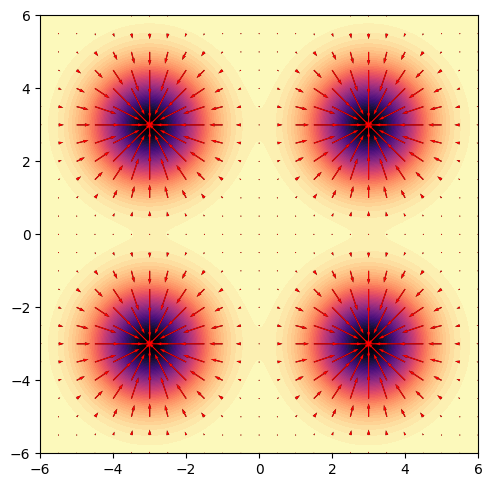

In [4]:
grid_lim = 6; grid_res = 25
xs = torch.linspace(-grid_lim, grid_lim, grid_res)
ys = torch.linspace(-grid_lim, grid_lim, grid_res)

fig, ax = plt.subplots(1, 1, figsize=(5,5))

X, Y, Z = potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500)
ax.contourf(X, Y, Z, levels=50, cmap='magma')

X, Y = torch.meshgrid(xs, ys, indexing="xy")
grid_points = torch.stack([X.flatten(), Y.flatten()], dim=-1).to(device)

with torch.no_grad():
    F_target = -grad_gaussian_potential_vectorized_torch(grid_points).cpu()

Xn, Yn = X.cpu().numpy(), Y.cpu().numpy()
U_t, V_t = F_target[:,0].reshape(grid_res,grid_res).numpy(), F_target[:,1].reshape(grid_res,grid_res).numpy()

ax.quiver(Xn, Yn, U_t, V_t)
ax.set_xlim(-grid_lim, grid_lim)
ax.set_ylim(-grid_lim, grid_lim)
ax.set_aspect('equal')

xc = np.linspace(xmin, xmax, 25)
yc = np.linspace(ymin, ymax, 25)
Xc, Yc = np.meshgrid(xc, yc)

U = np.zeros_like(Xc)
V_ = np.zeros_like(Xc)
Unorm = np.zeros_like(Xc)
Vnorm = np.zeros_like(Xc)
magnitude = np.zeros_like(Xc)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x_ = np.array([Xc[i, j], Yc[i, j]])
        f = -gradV(x_)
        U[i, j] = f[0]
        V_[i, j] = f[1]
        magnitude[i, j] = np.linalg.norm(f) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]

ax.quiver(Xc, Yc, U, V_, color = 'red')

plt.tight_layout()
plt.show()

In [5]:
V_0 = np.empty(mu.shape[1])

for i in range(0,mu.shape[1]):
    V_0[i] = V(mu[:,i])

In [6]:
def compute_c_stars(y, V0, delta=0.125, lambda_slack=None):
    K, d = y.shape
    c_stars = []
    statuses = []

    for i in range(K):
        c = cp.Variable(d)
        constraints = []
        slacks = []
        for j in range(K):
            if j == i: continue
            rhs = V0[i] - V0[j] + delta
            if lambda_slack is None:
                constraints.append((c @ (y[i] - y[j])) >= rhs)
            else:
                xi = cp.Variable(nonneg=True)
                slacks.append(xi)
                constraints.append((c @ (y[i] - y[j])) >= rhs - xi)

        if lambda_slack is None:
            obj = cp.Minimize(0.5 * cp.sum_squares(c))
            prob = cp.Problem(obj, constraints)
        else:
            obj = cp.Minimize(0.5 * cp.sum_squares(c) + lambda_slack * cp.sum(slacks))
            prob = cp.Problem(obj, constraints)

        prob.solve(solver=cp.OSQP)
        if prob.status not in ["infeasible", "unbounded"]:
            c_val = c.value
            c_stars.append(c_val)
            statuses.append(prob.status)
        else:
            c_stars.append(None)
            statuses.append(prob.status)

    return c_stars, statuses


c_stars, statuses = compute_c_stars(mu.T, V_0)

Now, we will start with a very simple one hot encoding for each of the 4 minima, then move onto something more complex. We solve for the $(G_s,d)$ using regularised regression.

In [7]:
l = 4
C = np.array(c_stars)
S = np.eye(l)

a1, a2  = S.shape
S_aug = np.concatenate([S, np.ones((a1,1))], axis=1)
lam = 1e-6
A_ = S_aug.T @ S_aug + lam*np.eye(a2+1)
B_ = S_aug.T @ C
Theta = np.linalg.solve(A_, B_)     
G_s = Theta[:-1,:].T       
d = Theta[-1,:]   

In [9]:
def V_mod(x, c):
    return V(x) - np.dot(c,x)

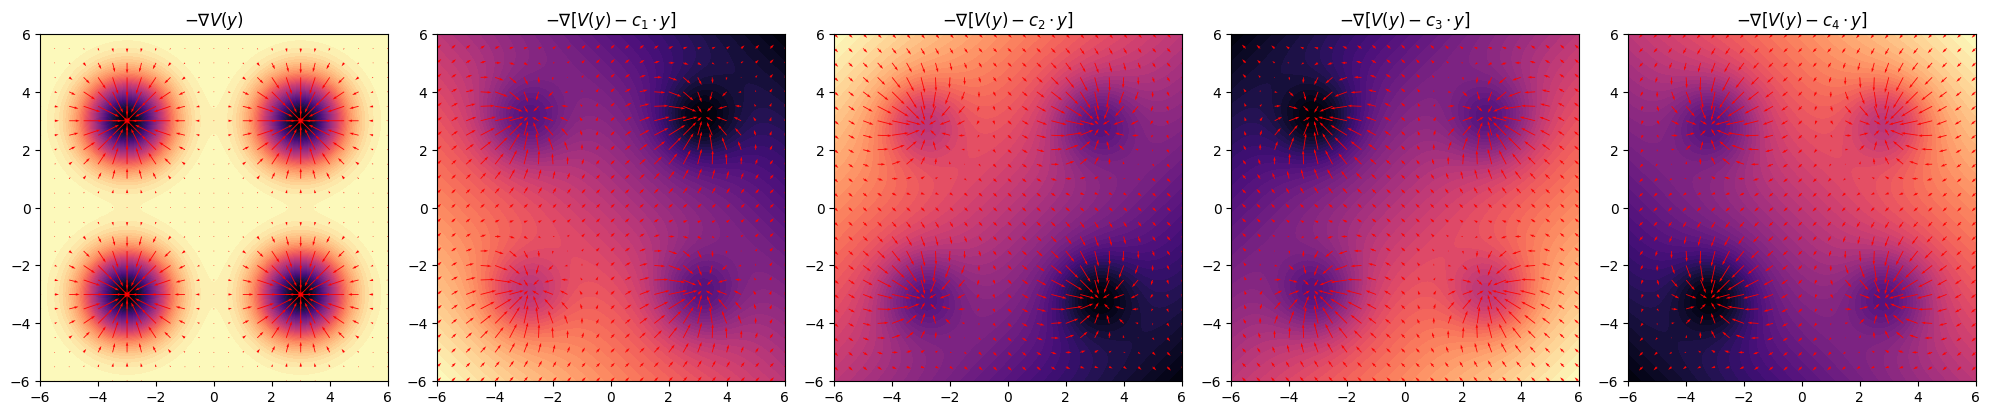

In [10]:
fig, ax = plt.subplots(1, 5, figsize=(20,4))

X, Y, Z = potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500)

xc = np.linspace(xmin, xmax, 25)
yc = np.linspace(ymin, ymax, 25)
Xc, Yc = np.meshgrid(xc, yc)

for k in range(0,5):
    
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            if k == 0:
                Z[i,j] = V(x)
            else:
                Z[i,j] = V_mod(x, C[k-1,:])
    ax[k].contourf(X, Y, Z, levels=50, cmap='magma')
    ax[k].set_aspect('equal')
    U = np.zeros_like(Xc)
    V_ = np.zeros_like(Xc)
    Unorm = np.zeros_like(Xc)
    Vnorm = np.zeros_like(Xc)
    magnitude = np.zeros_like(Xc)
    
    for i in range(Xc.shape[0]):
        for j in range(Xc.shape[1]):
            x_ = np.array([Xc[i, j], Yc[i, j]])
            if k == 0:
                f = -gradV(x_)
            else:
                f = -gradV(x_) + G_s@S[k-1,:] + d
            U[i, j] = f[0]
            V_[i, j] = f[1]
            magnitude[i, j] = np.linalg.norm(f) + 1e-11
            Unorm[i, j] = U[i, j] / magnitude[i, j]
            Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    
    ax[k].quiver(Xc, Yc, U, V_, color = 'red')

    if k==0:
        ax[k].set_title(r'$-\nabla V(y)$')
    else:
        ax[k].set_title(fr'$-\nabla [V(y) - c_{{{k}}} \cdot y]$')

#plt.savefig("switching_potentials.pdf", bbox_inches='tight', pad_inches=0.1, dpi=600)    
plt.tight_layout()
plt.show()

In [11]:
def simulate_process_EM(F,X0,T,dt,nu):

    Nt = int(T/dt)
    M = np.shape(X0)[0]
    X = np.zeros((M,Nt))
    X[:,0] = X0
    
    for t in trange(Nt-1, desc="Simulating", leave=False):
        X[:,t+1] = X[:,t] + dt*(F(X[:,t])) + nu*np.random.normal(0, np.sqrt(dt), size=M)
        
    return X

In [12]:
def f(x, c = None):
    if c is None:
        return -gradV(x)
    else:
        return -gradV(x) + c

X0 = np.array([0,0])
T_t = 500; dt = 0.01;
time = np.linspace(0,T_t,int(T_t/dt))

trajs = []
for i in range(0,5):
    if i==0:
        def g(x):
            c = None
            return f(x,c)
    if i!=0:
        def g(x):
            c = C[i-1,:]
            return f(x,c)
    
    trajs.append(simulate_process_EM(g,X0,T_t,dt,nu))

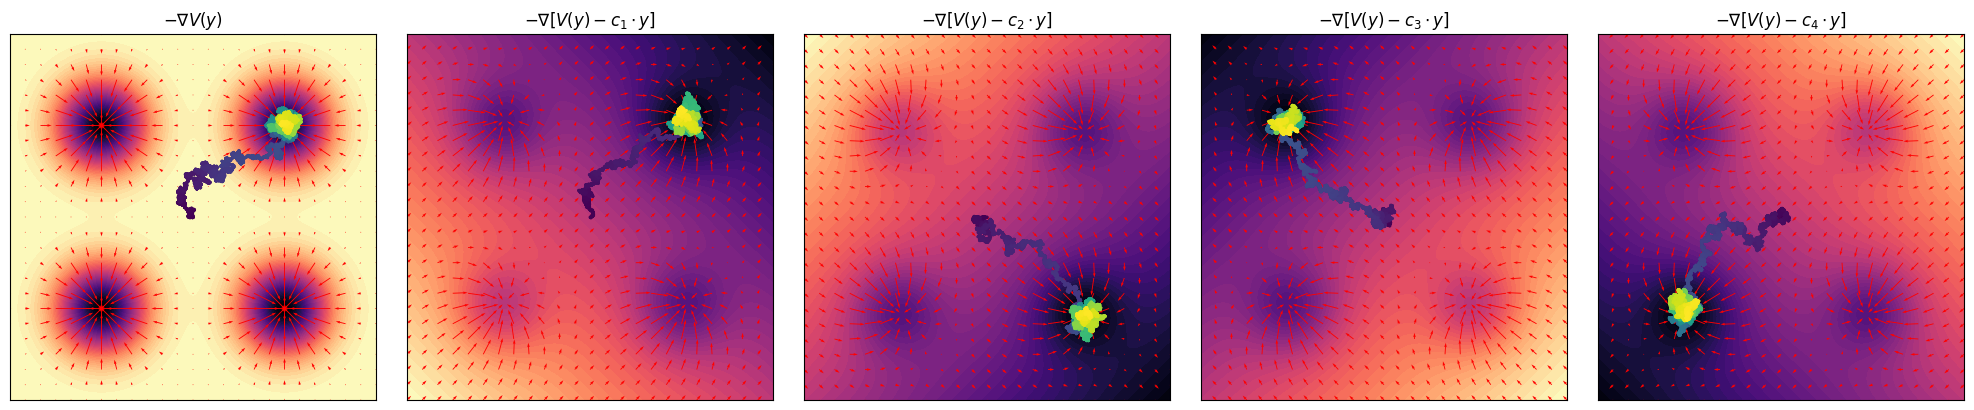

In [19]:
fig, ax = plt.subplots(1, 5, figsize=(20,4))

X, Y, Z = potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500)

xc = np.linspace(xmin, xmax, 25)
yc = np.linspace(ymin, ymax, 25)
Xc, Yc = np.meshgrid(xc, yc)

time = np.linspace(0,T_t,int(T_t/dt))
ds = 1

for k in range(0,5):
    
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            if k == 0:
                Z[i,j] = V(x)
            else:
                Z[i,j] = V_mod(x, C[k-1,:])
    cs = ax[k].contourf(X, Y, Z, levels=50, cmap='magma')
    cs.set_edgecolor("face")
    ax[k].set_aspect('equal')
    U = np.zeros_like(Xc)
    V_ = np.zeros_like(Xc)
    Unorm = np.zeros_like(Xc)
    Vnorm = np.zeros_like(Xc)
    magnitude = np.zeros_like(Xc)
    
    for i in range(Xc.shape[0]):
        for j in range(Xc.shape[1]):
            x_ = np.array([Xc[i, j], Yc[i, j]])
            if k == 0:
                f = -gradV(x_)
            else:
                f = -gradV(x_) + G_s@S[k-1,:] + d
            U[i, j] = f[0]
            V_[i, j] = f[1]
            magnitude[i, j] = np.linalg.norm(f) + 1e-11
            Unorm[i, j] = U[i, j] / magnitude[i, j]
            Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    
    ax[k].quiver(Xc, Yc, U, V_, color = 'red')
    ax[k].set_xticks([])
    ax[k].set_yticks([])
    traj = trajs[k]
    ax[k].scatter(traj[0,::ds],traj[1,::ds],c=time[::ds],cmap='viridis',s=1, rasterized = True)
    if k==0:
        ax[k].set_title(r'$-\nabla V(y)$')
    else:
        ax[k].set_title(fr'$-\nabla [V(y) - c_{{{k}}} \cdot y]$')


plt.tight_layout()
plt.show()

/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11301/528050216.py:26: UserWarning: linewidths is ignored by contourf
  cs = ax[k].contourf(
/var/folders/j3/3jf2wkbj5756yfdv4zjq5j300000gn/T/ipykernel_11301/528050216.py:26: UserWarning: The following kwargs were not used by contour: 'rasterized'
  cs = ax[k].contourf(


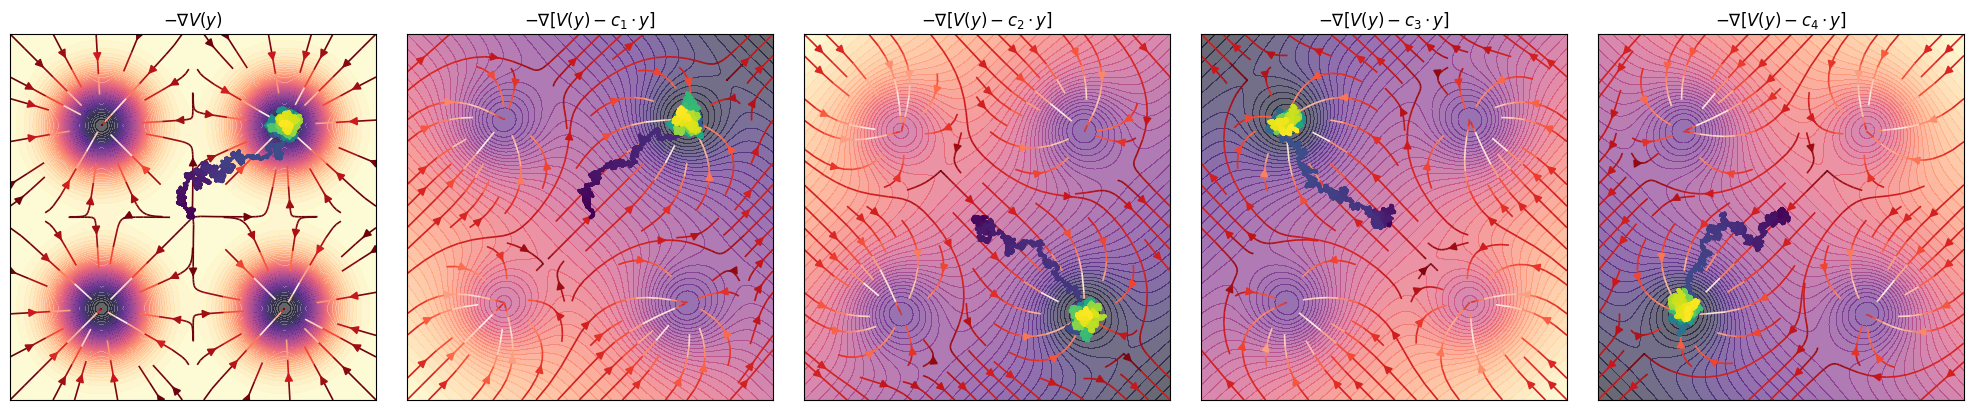

In [27]:
from matplotlib.colors import Normalize

fig, ax = plt.subplots(1, 5, figsize=(20,4), sharex=True, sharey=True)

X, Y, Z = potential_grid(V, xmin = xmin, xmax = xmax, ymin = ymin, ymax = ymax, no = 500)

xc = np.linspace(xmin, xmax, 25)
yc = np.linspace(ymin, ymax, 25)
Xc, Yc = np.meshgrid(xc, yc)

time = np.linspace(0,T_t,int(T_t/dt))
ds = 1

for k in range(0,5):
    
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            x = np.array([X[i, j], Y[i, j]])
            if k == 0:
                Z[i,j] = V(x)
            else:
                Z[i,j] = V_mod(x, C[k-1,:])
    
    cs = ax[k].contourf(
        X, Y, Z, 
        levels=50, 
        cmap='magma', 
        alpha=0.6, 
        antialiased=False, 
        linewidths=0,
        rasterized=True
    )
    ax[k].set_aspect('equal')
    
    U = np.zeros_like(Xc)
    V_ = np.zeros_like(Xc)
    
    for i in range(Xc.shape[0]):
        for j in range(Xc.shape[1]):
            x_ = np.array([Xc[i, j], Yc[i, j]])
            if k == 0:
                f = -gradV(x_)
            else:
                f = -gradV(x_) + G_s@S[k-1,:] + d
            U[i, j] = f[0]
            V_[i, j] = f[1]
            
    mag = np.sqrt(U**2 + V_**2)
    norm = Normalize(vmin=mag.min(), vmax=mag.max())
    
    ax[k].streamplot(
        xc, yc,                 
        U, V_,
        color=mag,           
        cmap='Reds_r', 
        norm=norm,
        density=0.6,            
        linewidth=1.2, 
        arrowsize=1.2,
        zorder=2  
    )

    ax[k].set_xlim([xmin, xmax])
    ax[k].set_ylim([ymin, ymax])
    
    ax[k].set_xticks([])
    ax[k].set_yticks([])
    
    traj = trajs[k]
    
    ax[k].scatter(
        traj[0,::ds], traj[1,::ds], 
        c=time[::ds], cmap='viridis', s=1, 
        rasterized=True, zorder=5
    )
    
    if k==0:
        ax[k].set_title(r'$-\nabla V(y)$')
    else:
        ax[k].set_title(fr'$-\nabla [V(y) - c_{{{k}}} \cdot y]$')

plt.tight_layout()
plt.show()

This works at the SDE level, let's try it at the network level.

In [8]:
class TwoLayerMLP(nn.Module):
    def __init__(self, latent_dim=64, num_noise_sources = 8):
        super().__init__()
        self.Gamma = nn.Linear(2, latent_dim, bias=False)   
        self.input_bias = nn.Parameter(torch.zeros(latent_dim))  
        self.W_s = nn.Linear(latent_dim, 2, bias= False)
        self.I_s = nn.Parameter(torch.zeros(2))
        self.B_s = nn.Parameter(torch.randn(2, num_noise_sources))

    def forward(self, x):
        z = self.Gamma(x) + self.input_bias       
        z = torch.tanh(z)
        out = -x + self.W_s(z) + self.I_s  
        return out

In [9]:
latent_dim = 256
model = TwoLayerMLP(latent_dim).to(device)

opt = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

n_samples = 25_000
x_train = (torch.rand(n_samples, 2) * 8.0 - 4.0).to(device)
y_train = -grad_gaussian_potential_vectorized_torch(x_train).to(device)
_eye2 = torch.eye(2, device=device)
D_target = (nu_t**2) * _eye2  

lambda_diff = 20
epochs = 30_000

for epoch in trange(epochs, desc= 'training MLP'):
    opt.zero_grad()
    
    
    pred = model(x_train)
    
    drift_loss = loss_fn(pred, y_train)

    D_model = model.B_s@(model.B_s.T)
    diffusion_loss = torch.norm(D_model - D_target, p='fro')**2
    
    loss = drift_loss + lambda_diff*diffusion_loss
    loss.backward()
    opt.step()
    
    if (epoch + 1) % 1000 == 0:
        print(f"epoch {epoch+1:4d} loss: {loss.item():.6f} drift: {drift_loss:.6f} diff: {diffusion_loss:.6f}")

training MLP:   3%|▊                       | 1009/30000 [00:12<05:41, 85.00it/s]

epoch 1000 loss: 81.916824 drift: 0.000748 diff: 4.095804


training MLP:   7%|█▌                      | 2010/30000 [00:24<05:41, 82.01it/s]

epoch 2000 loss: 15.630630 drift: 0.000201 diff: 0.781521


training MLP:  10%|██▍                     | 3009/30000 [00:35<05:12, 86.42it/s]

epoch 3000 loss: 4.328257 drift: 0.000118 diff: 0.216407


... (50 outputs left out)

training MLP:  97%|██████████████████████▏| 29010/30000 [06:14<00:11, 84.33it/s]

epoch 29000 loss: 0.000054 drift: 0.000054 diff: 0.000000


training MLP: 100%|███████████████████████| 30000/30000 [06:27<00:00, 77.46it/s]

epoch 30000 loss: 0.000015 drift: 0.000015 diff: 0.000000


In [10]:
print(model.B_s@(model.B_s.T))

Gamma = model.Gamma.weight.detach()
Gamma_pinv = torch.linalg.pinv(Gamma).detach()
b = model.input_bias.detach()
W = Gamma @ model.W_s.weight.detach() 
I = Gamma @ model.I_s.detach() +  b
B = Gamma @ model.B_s.detach()

print(Gamma_pinv@Gamma)

tensor([[ 1.0000e-02, -5.3449e-14],
        [-5.3449e-14,  1.0000e-02]], grad_fn=<MmBackward0>)
tensor([[ 1.0000e+00,  1.8626e-09],
        [-3.7253e-09,  1.0000e+00]])


In [11]:
def rnn_as_vector_field(y, Gamma, W, I, b, Gamma_pinv):
    u = y @ Gamma.T + b    
    g = - u + (torch.tanh(u) @ W.T) + I 
    return g@ Gamma_pinv.T

def rnn(y):
    return rnn_as_vector_field(y, Gamma, W, I, b, Gamma_pinv)

In [12]:
def integrate_rnn(W, I, B, dt, T, u0):

    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    Nt = int(T/dt)
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I) + np.sqrt(dt)*B@torch.randn((num_noise_sources,))

    return u

def project_rnn(u, Gamma, b, Gamma_pinv):
    return Gamma_pinv@((u.T - b).T)

def proj(u):
    return project_rnn(u, Gamma, b, Gamma_pinv)

Now, we introduce the RNN with (time-dependent) input.

In [17]:
G = Gamma @ torch.from_numpy(G_s.astype(np.float32)).to(device=device)
I = Gamma @ model.I_s.detach() + b + Gamma @ torch.from_numpy(d.astype(np.float32)).to(device=device)

def integrate_rnn_input(s, W, I, B, G, dt, T, u0):

    Nt, l = s.shape
    latent_dim = W.shape[0]
    num_noise_sources = B.shape[1]
    
    
    u = torch.zeros((latent_dim,Nt))
    u[:, 0] = u0

    for t in trange(0,Nt-1):
        u_ = u[:, t]
        u[:, t+1] = u_ + dt*(-u_ + W@torch.tanh(u_) + I + G@s[t]) + np.sqrt(dt)*2*B@torch.randn((num_noise_sources,))

    return u

In [16]:
y0 = torch.tensor([0.0, 0.0], dtype=torch.float32, device=Gamma.device)

dt = 0.01; T = 4000; u0 = Gamma @ y0 + b; Nt = int(T/dt)


k = 3
s = torch.from_numpy(np.tile(S[k,:], (Nt, 1)).astype(np.float32)).to(device=device)

u = integrate_rnn_input(s, W, I, B, G, dt, T, u0)

y = project_rnn(u, Gamma, b, Gamma_pinv)

NameError: name 'integrate_rnn_input' is not defined

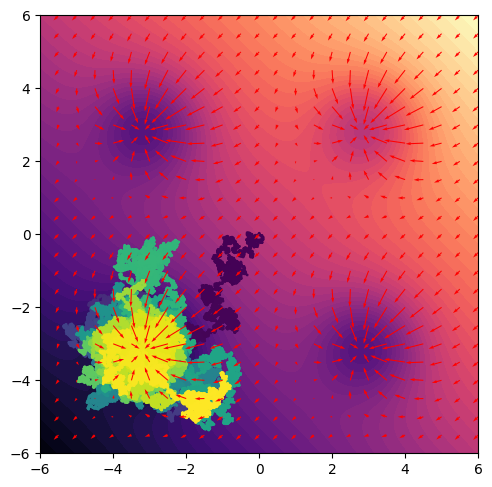

In [204]:
X, Y, Z = potential_grid(V)
Z = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        Z[i,j] = V_mod(x, C[k,:])
                
fig, ax = plt.subplots(1,1)
fig.set_size_inches(5,5)

time = np.linspace(0,T,int(T/dt))

ax.contourf(X, Y, Z, levels=50, cmap='magma')
ax.scatter(y[0,::ds], y[1,::ds],c=time[::ds],cmap='viridis',s=1)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x_ = np.array([Xc[i, j], Yc[i, j]])
        f = -gradV(x_) + G_s@S[k,:] + d
        U[i, j] = f[0]
        V_[i, j] = f[1]
        magnitude[i, j] = np.linalg.norm(f) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    
ax.quiver(Xc, Yc, U, V_, color = 'red')

ax.set_aspect('equal')
ax.set_xlim([xmin,xmax])
ax.set_ylim([ymin,ymax])

plt.tight_layout()
plt.show()

Let's try switching the input

In [216]:
dt = 0.01; T = 4000; u0 = Gamma @ y0 + b; Nt = int(T/dt)

s = torch.from_numpy((np.concat([np.tile(S[0,:], (int(Nt/2), 1)),np.tile(S[1,:], (int(Nt/2), 1))])).astype(np.float32)).to(device=device)
u = integrate_rnn_input(s, W, I, B, G, dt, T, u0)
y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 399999/399999 [00:11<00:00, 35464.92it/s]


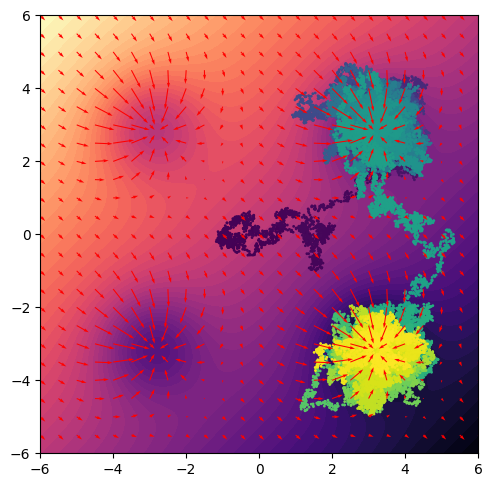

In [217]:
k = 1

X, Y, Z = potential_grid(V)
Z = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        Z[i,j] = V_mod(x, C[k,:])
                
fig, ax = plt.subplots(1,1)
fig.set_size_inches(5,5)

time = np.linspace(0,T,int(T/dt))

ax.contourf(X, Y, Z, levels=50, cmap='magma')
ax.scatter(y[0,::ds], y[1,::ds],c=time[::ds],cmap='viridis',s=1)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x_ = np.array([Xc[i, j], Yc[i, j]])
        f = -gradV(x_) + G_s@S[k,:] + d
        U[i, j] = f[0]
        V_[i, j] = f[1]
        magnitude[i, j] = np.linalg.norm(f) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    
ax.quiver(Xc, Yc, U, V_, color = 'red')

ax.set_aspect('equal')
ax.set_xlim([xmin,xmax])
ax.set_ylim([ymin,ymax])

plt.tight_layout()
plt.show()

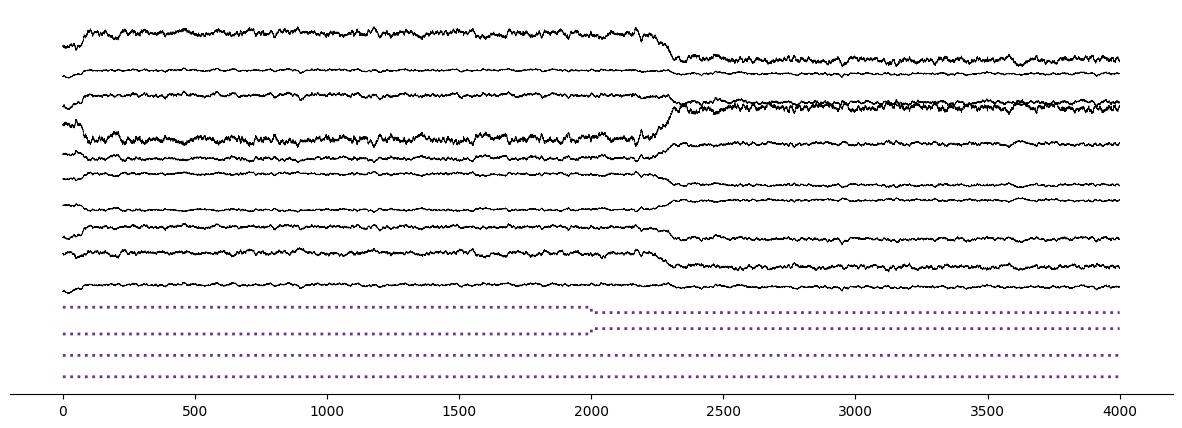

In [243]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(15,5)

t = np.linspace(0,T,Nt)

ds = 5
num_vis_neurons = 10
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    trace = u[v, ::ds] + 5*n- torch.mean(u[v, :])
    ax.plot(t[::ds],trace, 'black', linewidth = 0.5)

for i in range(0,l):
    plt.plot(t[::ds],s[::ds,i]-4*i-5, 'rebeccapurple', linewidth = 2, linestyle = 'dotted')
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)

plt.show()

Let's try random Gaussian inputs

In [13]:
l = 4
S = np.random.randn(l, 4)
S /= np.linalg.norm(S, axis=1, keepdims=True)

In [14]:
C = np.array(c_stars)

a1, a2  = S.shape
S_aug = np.concatenate([S, np.ones((a1,1))], axis=1)
lam = 1e-6
A_ = S_aug.T @ S_aug + lam*np.eye(a2+1)
B_ = S_aug.T @ C
Theta = np.linalg.solve(A_, B_)     
G_s = Theta[:-1,:].T       
d = Theta[-1,:]

G = Gamma @ torch.from_numpy(G_s.astype(np.float32)).to(device=device)
I = Gamma @ model.I_s.detach() + b + Gamma @ torch.from_numpy(d.astype(np.float32)).to(device=device)

In [49]:
s = torch.from_numpy((np.concat([np.tile(S[0,:], (int(Nt/2), 1)),np.tile(S[1,:], (int(Nt/2), 1))])).astype(np.float32)).to(device=device)
dt = 0.01; T = 4000; u0 = Gamma @ y0 + b; Nt = int(T/dt)
sigma_s = 0.05
noise = torch.randn_like(s) * sigma_s         
s_noisy = s + noise

In [50]:
u = integrate_rnn_input(s_noisy, W, I, B, G, dt, T, u0)
y = project_rnn(u, Gamma, b, Gamma_pinv)

100%|████████████████████████████████| 399999/399999 [00:11<00:00, 35301.58it/s]


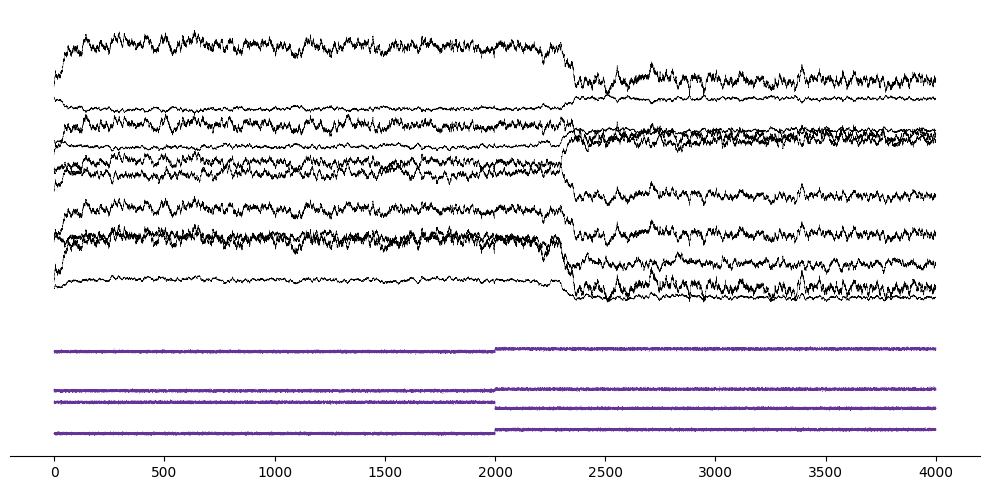

In [56]:
fig, ax = plt.subplots(1,1)
fig.set_size_inches(10,5)

t = np.linspace(0,T,Nt)

ds = 5
num_vis_neurons = 10
vis_neurons = np.random.choice(range(0,latent_dim),num_vis_neurons, replace=False)

for n, v in enumerate(vis_neurons):
    ax.plot(t[::ds],u[v, ::ds] + 2*n, 'black', linewidth = 0.25)

for i in range(0,l):
    plt.plot(t[::ds],1*s_noisy[::ds,i]-2*i-5, 'rebeccapurple', linewidth = 0.5, linestyle = 'dotted')
sns.despine(left = True)
plt.gca().get_yaxis().set_visible(False)
plt.tight_layout()
plt.show()

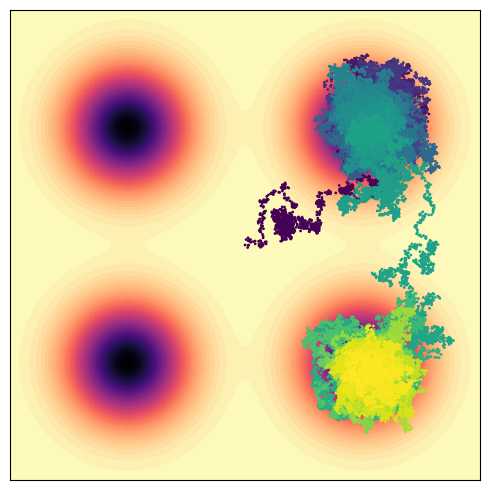

In [55]:
k = 1

X, Y, Z = potential_grid(V)
Z = np.zeros_like(X)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        x = np.array([X[i, j], Y[i, j]])
        Z[i,j] = V(x)
                
fig, ax = plt.subplots(1,1)
fig.set_size_inches(5,5)

time = np.linspace(0,T,int(T/dt))

cs = ax.contourf(X, Y, Z, levels=50, cmap='magma')
cs.set_edgecolor("face")
ax.scatter(y[0,::ds], y[1,::ds],c=time[::ds],cmap='viridis',s=1, rasterized = True)

for i in range(Xc.shape[0]):
    for j in range(Xc.shape[1]):
        x_ = np.array([Xc[i, j], Yc[i, j]])
        f = -gradV(x_) + G_s@S[k,:] + d
        U[i, j] = f[0]
        V_[i, j] = f[1]
        magnitude[i, j] = np.linalg.norm(f) + 1e-11
        Unorm[i, j] = U[i, j] / magnitude[i, j]
        Vnorm[i, j] = V_[i, j] / magnitude[i, j]
    
#ax.quiver(Xc, Yc, U, V_, color = 'red')

ax.set_aspect('equal')
ax.set_xlim([xmin,xmax])
ax.set_ylim([ymin,ymax])
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()